# Field experiment: analysis

Reproduces the field-experiment statistics and figures in the Results section
of the paper from the processed data in `data/` (built by `prepare_data.py`).


| file | unit | columns |
|---|---|---|
| `notes.csv` | experiment note that reached X | `noteId, postId, writer, status, coreNoteIntercept, coreNoteFactor1, numRatings` |
| `posts.csv` | randomized post | `postId, assigned_writer, baseline_decision, ca_decision, submitted, has_other_crh` |
| `ca_candidates.csv` | CA-writer candidate (10 per post) | `postId, run_idx, decision, pass_check, pred_helpfulness, pred_factor` |
| `ablation.csv` | randomized post | `baseline_note_valid, baseline_llm_judge, baseline_pred_helpfulness, baseline_pred_factor, ca_selected_run_idx, ca_selected_llm_judge` |

Writers: `baseline` (prompted LLM with an LLM submission judge) and `ca`
(community-aligned writer). Both writers ran on every post, so both decisions
are observed; only the randomly assigned writer's note was submitted. Note
status (CRH / CRNH / NMR), intercepts, factors and rating counts are from the
Community Notes data snapshot of 2026-09-29.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.proportion import (confint_proportions_2indep,
                                          proportion_confint, proportions_ztest)

DATA = Path("data")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

notes = pd.read_csv(DATA / "notes.csv", dtype={"noteId": str, "postId": str})
posts = pd.read_csv(DATA / "posts.csv", dtype={"postId": str})
cands = pd.read_csv(DATA / "ca_candidates.csv", dtype={"postId": str})
ablation = pd.read_csv(DATA / "ablation.csv", dtype={"postId": str})

# One row per randomized post with the assigned writer's note (if any).
assigned = posts.merge(notes.drop(columns="writer"), on="postId", how="left")
assigned["is_crh"] = assigned["status"] == "CRH"
assigned["is_crnh"] = assigned["status"] == "CRNH"

# Decision cell from both writers' observed submit/abstain decisions.
b_sub = posts["baseline_decision"] == "submit"
c_sub = posts["ca_decision"] == "submit"
CELL = pd.Series(np.select([b_sub & c_sub, ~b_sub & c_sub, b_sub & ~c_sub],
                           ["both", "ca_only", "baseline_only"], "neither"),
                 index=posts["postId"])
assigned["cell"] = assigned["postId"].map(CELL)
notes["cell"] = notes["postId"].map(CELL)

WRITERS = (("baseline", "Baseline", "#2962AC"),
           ("ca", "Community-aligned", "#F5A960"))
print(f"{len(posts)} posts, {len(notes)} submitted notes, {len(cands)} CA candidates")

4501 posts, 2571 submitted notes, 45010 CA candidates


In [2]:
# Statistical helpers

def proportion_z_test(k1, n1, k2, n2):
    # Two-sample pooled z-test of proportions. Returns (z, two-sided p).
    z, p = proportions_ztest(
        count=[k1, k2], nobs=[n1, n2], value=0,
        alternative="two-sided", prop_var=False,
    )
    return float(z), float(p)


def newcombe_diff_ci(k1, n1, k2, n2):
    # Newcombe 95% CI for the risk difference p1 - p2.
    lo, hi = confint_proportions_2indep(k1, n1, k2, n2, method="newcomb",
                                        compare="diff", alpha=0.05)
    return float(lo), float(hi)


def wilson_ci(k, n):
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return float(lo), float(hi)


def mcnemar_exact_p(b, c):
    # Two-sided exact (binomial) McNemar p from the two discordant counts.
    return float(stats.binomtest(min(b, c), n=b + c, p=0.5).pvalue)


def compare_arms(df, outcome, label):
    # CA vs baseline rate of a boolean outcome over each writer's rows.
    k = {w: int(df.loc[df["assigned_writer"] == w, outcome].sum()) for w, *_ in WRITERS}
    n = {w: int((df["assigned_writer"] == w).sum()) for w, *_ in WRITERS}
    rb, rc = k["baseline"] / n["baseline"], k["ca"] / n["ca"]
    lo, hi = newcombe_diff_ci(k["ca"], n["ca"], k["baseline"], n["baseline"])
    _, p = proportion_z_test(k["ca"], n["ca"], k["baseline"], n["baseline"])
    print(f"{label}")
    print(f"  baseline {k['baseline']}/{n['baseline']} = {rb:.2%}")
    print(f"  CA       {k['ca']}/{n['ca']} = {rc:.2%}")
    print(f"  difference (CA - baseline) = {100 * (rc - rb):.2f} pp, "
          f"95% CI [{100 * lo:.2f} pp, {100 * hi:.2f} pp]")
    print(f"  relative increase = {rc / rb - 1:.2%}")
    print(f"  two-sided two-sample proportion z-test p = {p:.3f}")


def passes_rm_gate(h, f):
    # CA submission rule: two-tier threshold on predicted helpfulness / |factor|.
    af = f.abs()
    return (((h > 0.35) & (af < 0.50))
            | ((h > 0.30) & (h <= 0.35) & (af < 0.35))).fillna(False)

## 1. CA writer increases the production of helpful notes

Primary outcome: the share of assigned posts that received a CRH note from the
assigned writer. Posts where the writer abstained, or where the submission failed, count as not CRH.

In [3]:
print(posts["assigned_writer"].value_counts().rename(index={"baseline": "baseline", "ca": "CA"}).to_string(), "\n")
compare_arms(assigned, "is_crh", "CRH per assigned post")

assigned_writer
baseline    2256
CA          2245 

CRH per assigned post
  baseline 117/2256 = 5.19%
  CA       151/2245 = 6.73%
  difference (CA - baseline) = 1.54 pp, 95% CI [0.16 pp, 2.93 pp]
  relative increase = 29.69%
  two-sided two-sample proportion z-test p = 0.029


### Figure: CRH outcomes (`figures/outcomes.png`)

CRH per assigned post, per submitted note, per stable note (at least 10
ratings, or CRH/CRNH status), and per rating (ratings on CRH notes / all
ratings on submitted notes). Error bars for the first three measures are 95% Wilson intervals. For the
rating share, 95% percentile bootstrap intervals resample randomized posts
within each arm (50,000 replicates; seed 20261020), keeping all ratings on a
note together. Posts without a submitted note contribute zero to numerator and
denominator. The rating-share difference is also reported with a bootstrap
interval and a two-sided, post-level delta-method Wald test; individual ratings
are not treated as independent observations.

assigned  baseline 117/2256 = 5.19% [4.34%, 6.18%]   CA 151/2245 = 6.73% [5.76%, 7.84%]   z-test p = 0.029
submitted baseline 117/1183 = 9.89% [8.32%, 11.72%]   CA 151/1388 = 10.88% [9.35%, 12.63%]   z-test p = 0.413
stable    baseline 117/834 = 14.03% [11.84%, 16.55%]   CA 151/981 = 15.39% [13.27%, 17.79%]   z-test p = 0.414
rating-share difference: 6.22 pp; post-bootstrap 95% CI [-2.49, 15.23] pp
rating    baseline 13463/80081 = 16.81% [12.35%, 21.80%]   CA 21860/94909 = 23.03% [16.01%, 30.88%]   post-level delta-method p = 0.177


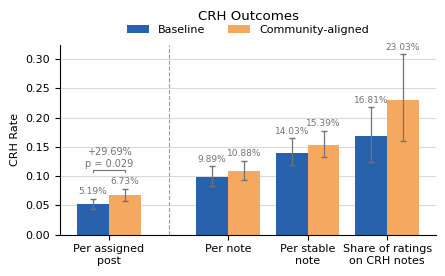

In [4]:
STABLE_MIN_RATINGS = 10
GROUPS = (("assigned", "Per assigned\npost", 0.0),
          ("submitted", "Per note", 1.5),
          ("stable", "Per stable\nnote", 2.5),
          ("rating", "Share of ratings\non CRH notes", 3.5))


def crh_counts(writer):
    sel = assigned[assigned["assigned_writer"] == writer]
    sub = notes[notes["writer"] == writer]
    stable = sub[(sub["numRatings"] >= STABLE_MIN_RATINGS)
                 | sub["status"].isin(["CRH", "CRNH"])]
    k = lambda df: int((df["status"] == "CRH").sum())
    return {"assigned": (int(sel["is_crh"].sum()), len(sel)),
            "submitted": (k(sub), len(sub)),
            "stable": (k(stable), len(stable)),
            "rating": (int(sub.loc[sub["status"] == "CRH", "numRatings"].sum()),
                       int(sub["numRatings"].sum()))}


# Resample at the randomization unit, preserving each note's rating cluster.
RATING_BOOTSTRAP_REPS = 50_000
rating_rng = np.random.default_rng(20261020)


def rating_share_uncertainty(writer):
    arm = assigned.loc[assigned["assigned_writer"] == writer]
    totals = arm["numRatings"].fillna(0).to_numpy(dtype=float)
    crh_totals = totals * arm["is_crh"].to_numpy(dtype=float)
    n = len(totals)
    share = crh_totals.sum() / totals.sum()
    draws = np.empty(RATING_BOOTSTRAP_REPS)
    for start in range(0, RATING_BOOTSTRAP_REPS, 500):
        stop = min(start + 500, RATING_BOOTSTRAP_REPS)
        indices = rating_rng.integers(0, n, size=(stop - start, n))
        draws[start:stop] = (crh_totals[indices].sum(axis=1)
                            / totals[indices].sum(axis=1))
    # Ratio-estimator influence values, one per randomized post.
    residuals = crh_totals - share * totals
    variance = residuals.var(ddof=1) / (n * totals.mean() ** 2)
    return {"ci": tuple(np.quantile(draws, [0.025, 0.975])),
            "draws": draws, "variance": variance}


rating_uncertainty = {w: rating_share_uncertainty(w) for w, *_ in WRITERS}


def outcome_ci(writer, key, k, n):
    if key == "rating":
        return rating_uncertainty[writer]["ci"]
    return wilson_ci(k, n)


counts = {w: crh_counts(w) for w, *_ in WRITERS}
for key, *_ in GROUPS:
    (kb, nb), (kc, nc) = counts["baseline"][key], counts["ca"][key]
    if key == "rating":
        difference = kc / nc - kb / nb
        se = np.sqrt(sum(v["variance"] for v in rating_uncertainty.values()))
        p = 2 * stats.norm.sf(abs(difference / se))
        diff_ci = np.quantile(rating_uncertainty["ca"]["draws"]
                              - rating_uncertainty["baseline"]["draws"], [0.025, 0.975])
        test_label = "post-level delta-method p"
        print(f"rating-share difference: {100 * difference:.2f} pp; "
              f"post-bootstrap 95% CI [{100 * diff_ci[0]:.2f}, {100 * diff_ci[1]:.2f}] pp")
    else:
        _, p = proportion_z_test(kc, nc, kb, nb)
        test_label = "z-test p"
    ci = {w: "[{:.2%}, {:.2%}]".format(*outcome_ci(w, key, *counts[w][key])) for w, *_ in WRITERS}
    print(f"{key:9s} baseline {kb}/{nb} = {kb / nb:.2%} {ci['baseline']}   "
          f"CA {kc}/{nc} = {kc / nc:.2%} {ci['ca']}   {test_label} = {p:.3g}")

plt.rcParams.update({"font.size": 8})
fig, ax = plt.subplots(figsize=(4.5, 2.8))
width, tops = 0.4, {}
for j, (writer, label, color) in enumerate(WRITERS):
    for key, _, x0 in GROUPS:
        k, n = counts[writer][key]
        rate, (lo, hi) = k / n, outcome_ci(writer, key, k, n)
        x = x0 + (j - 0.5) * width
        ax.bar(x, rate, width, color=color, linewidth=0, zorder=2,
               label=label if key == "assigned" else None)
        ax.errorbar(x, rate, yerr=[[rate - lo], [hi - rate]], fmt="none",
                    ecolor="0.45", elinewidth=0.9, capsize=2.5, zorder=3)
        ax.text(x, hi + 0.004, f"{rate:.2%}", ha="center", va="bottom",
                fontsize=6.5, color="0.45", zorder=4)
        tops[key] = max(tops.get(key, 0.0), hi)

# Significance bracket over the per-assigned-post pair only.
(kb, nb), (kc, nc) = counts["baseline"]["assigned"], counts["ca"]["assigned"]
_, p = proportion_z_test(kb, nb, kc, nc)
rel = (kc / nc) / (kb / nb) - 1
x0 = GROUPS[0][2]
xl, xr = x0 - width / 2, x0 + width / 2
y = tops["assigned"] + 0.032
ax.plot([xl, xl, xr, xr], [y - 0.004, y, y, y - 0.004], color="0.45", lw=0.8, zorder=4)
ax.text(x0, y + 0.002, f"{rel:+.2%}\np = {p:.3f}", ha="center", va="bottom",
        fontsize=7, color="0.45", linespacing=1.2, zorder=4)
ax.axvline((GROUPS[0][2] + GROUPS[1][2]) / 2, color="0.6", lw=0.8, ls="--", zorder=1)
ax.set_xticks([g[2] for g in GROUPS])
ax.set_xticklabels([g[1] for g in GROUPS])
ax.set_title("CRH Outcomes", pad=18)
ax.set_ylabel("CRH Rate")
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="0.85", lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
for suffix in (".pdf", ".png"):
    fig.savefig((FIGS / "outcomes").with_suffix(suffix), dpi=300, bbox_inches="tight")
plt.show()

## 2. The two writers achieve similar helpfulness when both choose to submit

Posts on which both writers independently decided to submit. Assignment is
randomized independently of these decisions, so the CRH rate per assigned post
within this subset is a causal comparison of note quality.

In [5]:
both = assigned[assigned["cell"] == "both"]
print(f"both-submit posts: {len(both)}\n")
compare_arms(both, "is_crh", "CRH per assigned post, both-submit subset")

ib = both.loc[both["assigned_writer"] == "baseline", "coreNoteIntercept"].dropna()
ic = both.loc[both["assigned_writer"] == "ca", "coreNoteIntercept"].dropna()
t = stats.ttest_ind(ic, ib, equal_var=False)
print(f"\ncoreNoteIntercept (scored notes): baseline n={len(ib)} mean={ib.mean():.3f}, "
      f"CA n={len(ic)} mean={ic.mean():.3f}; Welch two-sided t-test p = {t.pvalue:.3f}")

both-submit posts: 2170

CRH per assigned post, both-submit subset
  baseline 115/1096 = 10.49%
  CA       114/1074 = 10.61%
  difference (CA - baseline) = 0.12 pp, 95% CI [-2.47 pp, 2.72 pp]
  relative increase = 1.16%
  two-sided two-sample proportion z-test p = 0.926

coreNoteIntercept (scored notes): baseline n=709 mean=0.208, CA n=700 mean=0.196; Welch two-sided t-test p = 0.139


## 3. CA writer identifies additional helpful contribution opportunities

### Submission rates (all posts, paired)

In [6]:
nb_, nc_ = int(b_sub.sum()), int(c_sub.sum())
b, c = int((b_sub & ~c_sub).sum()), int((~b_sub & c_sub).sum())
print(f"submit rate: baseline {nb_}/{len(posts)} = {nb_ / len(posts):.2%}, "
      f"CA {nc_}/{len(posts)} = {nc_ / len(posts):.2%}")
print(f"exact McNemar (baseline-only {b}, CA-only {c}): p = {mcnemar_exact_p(b, c):.2g}\n")
print(CELL.value_counts().to_string())

submit rate: baseline 2392/4501 = 53.14%, CA 2805/4501 = 62.32%
exact McNemar (baseline-only 222, CA-only 635): p = 8.1e-47

both             2170
neither          1474
ca_only           635
baseline_only     222


### Disagreement cells

In [7]:
ca_only = assigned[(assigned["cell"] == "ca_only") & (assigned["assigned_writer"] == "ca")]
print(f"CA-only posts: {(CELL == 'ca_only').sum()}; assigned to CA: {len(ca_only)}; "
      f"CA CRH {ca_only['is_crh'].sum()}/{len(ca_only)} = {ca_only['is_crh'].mean():.2%}")

base_only = assigned[(assigned["cell"] == "baseline_only")
                     & (assigned["assigned_writer"] == "baseline")]
print(f"\nbaseline-only posts: {(CELL == 'baseline_only').sum()}; assigned to baseline: "
      f"{len(base_only)}; baseline CRH notes: {base_only['is_crh'].sum()}")

r_bo = notes.loc[(notes["cell"] == "baseline_only") & (notes["writer"] == "baseline"), "numRatings"]
r_both = notes.loc[notes["cell"] == "both", "numRatings"]
print(f"median ratings: baseline notes on baseline-only posts {r_bo.median():g} "
      f"vs notes on both-submit posts {r_both.median():g}")

CA-only posts: 635; assigned to CA: 326; CA CRH 37/326 = 11.35%

baseline-only posts: 222; assigned to baseline: 101; baseline CRH notes: 2
median ratings: baseline notes on baseline-only posts 47.5 vs notes on both-submit posts 20


### CA candidates on baseline-only posts

The CA writer's candidate pool on posts where it abstained but the baseline
submitted. "Best note" is the valid candidate (wrote a note that passed the
length/citation check) with the highest predicted helpfulness.

In [8]:
n_write = cands[cands["decision"] == "write"].groupby("postId").size()
bo_posts = CELL.index[CELL == "baseline_only"]
print(f"baseline-only posts where CA wrote >= 1 candidate: "
      f"{(n_write.reindex(bo_posts, fill_value=0) >= 1).sum()}/{len(bo_posts)}")

valid = cands[cands["pass_check"]]
best = (valid.sort_values(["pred_helpfulness", "run_idx"], ascending=[False, True])
        .drop_duplicates("postId").set_index("postId"))
best["cell"] = CELL.reindex(best.index)
best["abs_factor"] = best["pred_factor"].abs()
print(best.groupby("cell")[["pred_helpfulness", "abs_factor"]].agg(["mean", "size"]).round(3))

baseline-only posts where CA wrote >= 1 candidate: 215/222
              pred_helpfulness       abs_factor      
                          mean  size       mean  size
cell                                                 
baseline_only            0.306   214      0.403   214
both                     0.432  2170      0.126  2170
ca_only                  0.420   635      0.114   635
neither                  0.328   283      0.246   283


### Figure: outcomes by decision cell (`figures/opportunities.png`)

(a) CRH rate over each writer's assigned posts in the cell (platform-rejected
submissions count as not CRH), 95% Wilson intervals. (b) coreNoteFactor1 vs
coreNoteIntercept of the submitted notes; unscored notes are dropped.

Both submit   Baseline          CRH 115/1096 = 0.1049 CI [0.0881, 0.1245]
Both submit   Community-aligned CRH 114/1074 = 0.1061 CI [0.0891, 0.1260]
CA-only       Community-aligned CRH 37/326 = 0.1135 CI [0.0835, 0.1525]
Baseline-only Baseline          CRH 2/101 = 0.0198 CI [0.0054, 0.0693]
Both submit   Baseline          scored 709/1083  mean intercept 0.2078  mean |factor| 0.2915
Both submit   Community-aligned scored 700/1063  mean intercept 0.1963  mean |factor| 0.2946
CA-only       Community-aligned scored 241/325  mean intercept 0.1702  mean |factor| 0.2900
Baseline-only Baseline          scored 81/100  mean intercept 0.1942  mean |factor| 0.4597


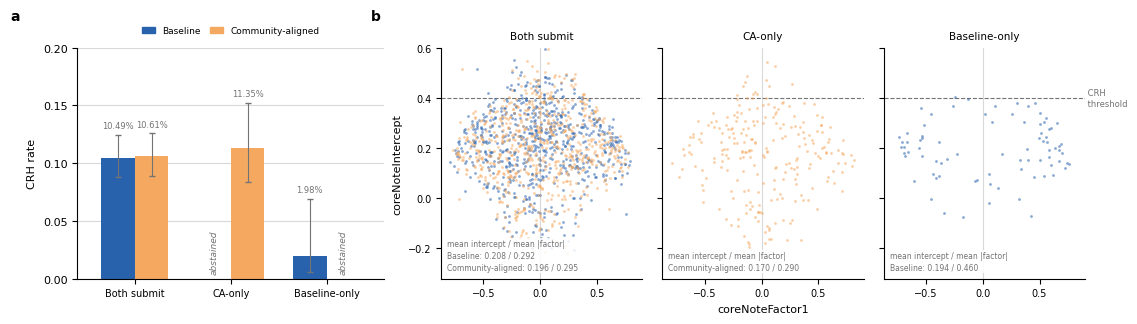

In [9]:
CRH_INTERCEPT = 0.40
GREY = "0.45"
CELLS = (("both", "Both submit", True, True),
         ("ca_only", "CA-only", True, False),
         ("baseline_only", "Baseline-only", False, True))

plt.rcParams.update({"font.size": 8})
fig = plt.figure(figsize=(13, 3.0))
outer = fig.add_gridspec(1, 2, width_ratios=[1, 2.1], wspace=0.12)
ax_bar = fig.add_subplot(outer[0])
right = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[1], wspace=0.1)
ax_sc = [fig.add_subplot(right[0])]
ax_sc += [fig.add_subplot(right[k], sharex=ax_sc[0], sharey=ax_sc[0]) for k in (1, 2)]
for ax in ax_sc[1:]:
    ax.tick_params(labelleft=False)

# Panel a: CRH rate per assigned post, per writer and cell.
width = 0.35
for i, (key, label, ca_submits, base_submits) in enumerate(CELLS):
    for j, (writer, wlabel, color) in enumerate(WRITERS):
        submits = base_submits if writer == "baseline" else ca_submits
        x = i + (j - 0.5) * width
        if not submits:
            ax_bar.text(x, 0.004, "abstained", ha="center", va="bottom", rotation=90,
                        fontsize=6.5, color=GREY, style="italic")
            continue
        sel = assigned[(assigned["assigned_writer"] == writer) & (assigned["cell"] == key)]
        k, n = int(sel["is_crh"].sum()), len(sel)
        rate, (lo, hi) = k / n, wilson_ci(k, n)
        ax_bar.bar(x, rate, width, color=color, linewidth=0, zorder=2)
        ax_bar.errorbar(x, rate, yerr=[[rate - lo], [hi - rate]], fmt="none",
                        ecolor=GREY, elinewidth=0.8, capsize=2.2, zorder=3)
        ax_bar.text(x, hi + 0.004, f"{rate:.2%}", ha="center", va="bottom",
                    fontsize=6, color=GREY, zorder=4)
        print(f"{label:13s} {wlabel:17s} CRH {k}/{n} = {rate:.4f} CI [{lo:.4f}, {hi:.4f}]")
ax_bar.set_xticks(range(3))
ax_bar.set_xticklabels([c[1] for c in CELLS], fontsize=7)
ax_bar.set_xlim(-0.6, 2.6)
ax_bar.set_ylabel("CRH rate")
ax_bar.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax_bar.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax_bar.set_ylim(0, 0.20)
ax_bar.grid(axis="y", color="0.85", lw=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.spines[["top", "right"]].set_visible(False)
ax_bar.legend(handles=[Patch(color=c, label=l) for _, l, c in WRITERS], frameon=False,
              ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=6.5,
              columnspacing=1.0, handlelength=1.5)

# Panel b: factor vs intercept of submitted notes, one axes per cell.
scored = notes.dropna(subset=["coreNoteIntercept", "coreNoteFactor1"])
for ax, (key, label, *_rest) in zip(ax_sc, CELLS):
    means = ["mean intercept / mean |factor|"]
    for writer, wlabel, color in WRITERS:
        n_all = int(((notes["writer"] == writer) & (notes["cell"] == key)).sum())
        if n_all == 0:
            continue
        sel = scored[(scored["writer"] == writer) & (scored["cell"] == key)]
        ax.scatter(sel["coreNoteFactor1"], sel["coreNoteIntercept"], s=4, color=color,
                   alpha=0.55, linewidths=0, zorder=2)
        m_int, m_fac = sel["coreNoteIntercept"].mean(), sel["coreNoteFactor1"].abs().mean()
        means.append(f"{wlabel}: {m_int:.3f} / {m_fac:.3f}")
        print(f"{label:13s} {wlabel:17s} scored {len(sel)}/{n_all}  "
              f"mean intercept {m_int:.4f}  mean |factor| {m_fac:.4f}")
    ax.text(0.03, 0.03, "\n".join(means), transform=ax.transAxes, ha="left", va="bottom",
            fontsize=5.5, color=GREY, linespacing=1.4, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.0))
    ax.axhline(CRH_INTERCEPT, color=GREY, lw=0.8, ls="--", zorder=1)
    ax.axvline(0, color="0.85", lw=0.8, zorder=0)
    ax.set_title(label, fontsize=7.5)
    ax.set_ylim(top=0.6)
    ax.set_xticks([-0.5, 0, 0.5])
    ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
ax_sc[0].set_ylabel("coreNoteIntercept")
ax_sc[1].set_xlabel("coreNoteFactor1")
ax_sc[-1].text(1.0, CRH_INTERCEPT, " CRH\n threshold",
               transform=ax_sc[-1].get_yaxis_transform(), ha="left", va="center",
               fontsize=6, color=GREY)
ax_bar.text(-0.22, 1.12, "a", transform=ax_bar.transAxes, fontsize=10, fontweight="bold")
ax_sc[0].text(-0.35, 1.12, "b", transform=ax_sc[0].transAxes, fontsize=10, fontweight="bold")
fig.savefig(FIGS / "opportunities.png", dpi=300, bbox_inches="tight")
plt.show()

### Posts with a non-experimental CRH note

A non-experimental CRH note is a misleading-classified note written outside
the experiment whose status is CRH in the 2026-09-29 snapshot.

In [10]:
oc = posts["has_other_crh"]
b_abs, c_abs = ~b_sub[oc], ~c_sub[oc]
n_oc = int(oc.sum())
b, c = int((b_abs & ~c_abs).sum()), int((~b_abs & c_abs).sum())
print(f"posts with a non-experimental CRH note: {n_oc}")
print(f"declined to submit: baseline {b_abs.sum()}/{n_oc} = {b_abs.mean():.1%}, "
      f"CA {c_abs.sum()}/{n_oc} = {c_abs.mean():.1%}")
print(f"exact McNemar (baseline-only abstain {b}, CA-only abstain {c}): "
      f"p = {mcnemar_exact_p(b, c):.2g}")

posts with a non-experimental CRH note: 692
declined to submit: baseline 236/692 = 34.1%, CA 139/692 = 20.1%
exact McNemar (baseline-only abstain 111, CA-only abstain 14): p = 6.6e-20


### CRNH notes by decision cell

CRNH rate over each writer's assigned posts in the cell. Candidate disagreement: fewer than half of the ten CA candidates chose to write.

In [11]:
for key, label, *_ in CELLS:
    for writer, wlabel, _ in WRITERS:
        sel = assigned[(assigned["assigned_writer"] == writer) & (assigned["cell"] == key)]
        if (sel["status"].notna()).any():
            print(f"{label:13s} {wlabel:17s} CRNH {int(sel['is_crnh'].sum())}/{len(sel)} "
                  f"= {sel['is_crnh'].mean():.2%}")
both_ca = both[both["assigned_writer"] == "ca"]
both_b = both[both["assigned_writer"] == "baseline"]
_, p = proportion_z_test(int(both_ca["is_crnh"].sum()), len(both_ca),
                         int(both_b["is_crnh"].sum()), len(both_b))
print(f"both-submit CRNH, CA vs baseline: two-sided z-test p = {p:.3f}\n")

crnh = ca_only[ca_only["is_crnh"]]
low = n_write.reindex(crnh["postId"], fill_value=0) < 5
print(f"CA-only CRNH notes: {len(crnh)}; with fewer than 5/10 candidates writing: {low.sum()}")

Both submit   Baseline          CRNH 34/1096 = 3.10%
Both submit   Community-aligned CRNH 44/1074 = 4.10%
CA-only       Community-aligned CRNH 27/326 = 8.28%
Baseline-only Baseline          CRNH 2/101 = 1.98%
both-submit CRNH, CA vs baseline: two-sided z-test p = 0.213

CA-only CRNH notes: 27; with fewer than 5/10 candidates writing: 19


## 4. Understanding the contributions of simulated feedback

Retrospective analyses of the logged candidates and decisions on all 4,501
posts. The post-level indicator is `has_other_crh`.

### Candidate selection: random vs CA selection

Both procedures keep the CA submission rule (consensus of at least 2 of 10
candidates writing, and the two-tier reward-model gate). *Random*: pick one of
the ten candidates uniformly; submit if it is a valid note that passes the
gate. Its submission probability per post is exactly (# valid gate-passing
candidates) / 10, so rates are ratios of expected counts. *CA selection*: pick
the valid candidate with the highest predicted helpfulness, then apply the gate.

In [12]:
cands["ok_gate"] = cands["pass_check"] & passes_rm_gate(cands["pred_helpfulness"],
                                                        cands["pred_factor"])
per_post = cands.groupby("postId").agg(n_write=("decision", lambda d: (d == "write").sum()),
                                       n_gate=("ok_gate", "sum"))
per_post = per_post.reindex(posts["postId"])
consensus = per_post["n_write"] >= 2
oc = posts.set_index("postId")["has_other_crh"]

w_random = per_post["n_gate"] / 10 * consensus
w_ca = best["pred_helpfulness"].notna().reindex(per_post.index, fill_value=False) & \
    passes_rm_gate(best["pred_helpfulness"], best["pred_factor"]).reindex(per_post.index, fill_value=False)
w_ca = w_ca.astype(float) * consensus
for name, w in (("random selection", w_random), ("CA selection", w_ca)):
    print(f"{name:17s} submits on {w.sum():.1f}/{len(w)} = {w.mean():.2%} of posts; "
          f"{(w * oc).sum() / w.sum():.2%} of submitted posts have a non-experimental CRH note "
          f"({(w * oc).sum() / len(w):.1%} of all posts)")

random selection  submits on 2000.5/4501 = 44.45% of posts; 22.10% of submitted posts have a non-experimental CRH note (9.8% of all posts)
CA selection      submits on 2772.0/4501 = 61.59% of posts; 19.84% of submitted posts have a non-experimental CRH note (12.2% of all posts)


### Submission criteria: CA rule vs LLM judge on the same notes

Baseline notes: every valid baseline note with a logged LLM-judge decision,
scored by the reward model. CA-selected notes: the highest-predicted-helpfulness
valid CA candidate per post, judged by the same LLM judge. Rates are the share of posts with a
non-experimental CRH note, by gate decision.

In [13]:
a = ablation.merge(posts[["postId", "has_other_crh"]], on="postId")


def gate_table(df, label):
    print(f"{label}: {len(df)} notes")
    for gate in ("rm_pass", "llm_pass"):
        name = "CA rule  " if gate == "rm_pass" else "LLM judge"
        p, r = df[df[gate]], df[~df[gate]]
        print(f"  {name} approves {len(p)}/{len(df)} = {len(p) / len(df):.1%}; "
              f"non-experimental CRH: approved {p['has_other_crh'].mean():.1%}, "
              f"rejected {r['has_other_crh'].mean():.1%} (n={len(r)})")


base = a[a["baseline_llm_judge"].notna()].copy()
base["llm_pass"] = base["baseline_llm_judge"].astype(bool)
base["rm_pass"] = passes_rm_gate(base["baseline_pred_helpfulness"], base["baseline_pred_factor"])
gate_table(base, "Baseline notes")

sel = a[a["ca_selected_llm_judge"].notna()].copy()
sel["llm_pass"] = sel["ca_selected_llm_judge"].astype(bool)
sel = sel.merge(cands[["postId", "run_idx", "ok_gate"]],
                left_on=["postId", "ca_selected_run_idx"], right_on=["postId", "run_idx"])
sel["rm_pass"] = sel["ok_gate"]
print()
gate_table(sel, "CA-selected candidate notes")

Baseline notes: 2493 notes
  CA rule   approves 2023/2493 = 81.1%; non-experimental CRH: approved 21.7%, rejected 8.9% (n=470)
  LLM judge approves 2392/2493 = 95.9%; non-experimental CRH: approved 19.1%, rejected 24.8% (n=101)

CA-selected candidate notes: 3302 notes
  CA rule   approves 2912/3302 = 88.2%; non-experimental CRH: approved 19.5%, rejected 6.2% (n=390)
  LLM judge approves 3096/3302 = 93.8%; non-experimental CRH: approved 18.3%, rejected 12.6% (n=206)
